# ML1 - GridSearch avec DecisionTreeRegresson, RandomForestRegressor

Ce notebook fait suite au notebook ML1_Pipeline_Model et se concentre sur :
1. L'utilisation de DecisionTreeRegressor et RandomForestRegressor ou d'autres
2. L'optimisation des hyperparamètres avec GridSearchCV
3. La validation croisée (cross-validation)

## 1. Import des bibliothèques

In [27]:
# Les libraries nécessaires
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV , cross_validate
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score



## 2. Chargement et préparation des données avec le PipeLine.

Nous reprenons les mêmes étapes de préparation que dans le notebook précédent.

In [28]:
# Chargement des données depuis le fichier pickle
df = pd.read_pickle('data/arbres_clean.pkl')

X = df.drop('anneedeplantation', axis=1)
y = df['anneedeplantation']

num_cols = X.select_dtypes(include='number').columns
cat_cols = X.select_dtypes(exclude='number').columns

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])


## 3. Cross-validation initiale

Avant d'optimiser les hyperparamètres, évaluons un modèle avec les paramètres par défaut en utilisant la validation croisée.

In [29]:
# Validation croisée initiale sans optimisation des hyperparamètres
# On peut aussi imprimer les scores MSE ou MAE de chaque cross-validation.
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2, random_state=42) 

kf = KFold(n_splits=5, shuffle=True, random_state=42)
def evaluer(model, nom):
    res = cross_validate(
        model, X_train, y_train, cv=kf, n_jobs=-1,
        scoring=['neg_mean_squared_error', 'neg_mean_absolute_error', 'r2']
    )
    mse = -res['test_neg_mean_squared_error']
    mae = -res['test_neg_mean_absolute_error']
    rmse = np.sqrt(mse)
    r2 = res['test_r2']

    print(f"===== {nom} =====")
    for i, (a, b, c, d) in enumerate(zip(mse, mae, rmse, r2), start=1):
        print(f"Fold {i} : MSE = {a:.2f} | MAE = {b:.2f} | RMSE = {c:.2f} | R² = {d:.3f}")

    print(f"\nMoyenne    : MSE = {mse.mean():.2f} | MAE = {mae.mean():.2f} | RMSE = {rmse.mean():.2f} | R² = {r2.mean():.3f}")
    print(f"Écart-type : MSE = {mse.std():.2f} | MAE = {mae.std():.2f} | RMSE = {rmse.std():.2f} | R² = {r2.std():.3f}\n")

model_dt = Pipeline([('prep', preprocessor),
                     ('model', DecisionTreeRegressor(random_state=42))])
model_rf = Pipeline([('prep', preprocessor),
                     ('model', RandomForestRegressor(random_state=42, n_jobs=-1))])

evaluer(model_dt, "Arbre (défaut)")
evaluer(model_rf, "Forêt (défaut)")

===== Arbre (défaut) =====
Fold 1 : MSE = 44.52 | MAE = 1.85 | RMSE = 6.67 | R² = 0.863
Fold 2 : MSE = 47.39 | MAE = 1.87 | RMSE = 6.88 | R² = 0.857
Fold 3 : MSE = 47.92 | MAE = 1.84 | RMSE = 6.92 | R² = 0.859
Fold 4 : MSE = 46.86 | MAE = 1.90 | RMSE = 6.85 | R² = 0.858
Fold 5 : MSE = 46.59 | MAE = 1.84 | RMSE = 6.83 | R² = 0.860

Moyenne    : MSE = 46.66 | MAE = 1.86 | RMSE = 6.83 | R² = 0.859
Écart-type : MSE = 1.16 | MAE = 0.02 | RMSE = 0.09 | R² = 0.002

===== Forêt (défaut) =====
Fold 1 : MSE = 29.80 | MAE = 2.04 | RMSE = 5.46 | R² = 0.909
Fold 2 : MSE = 29.14 | MAE = 2.00 | RMSE = 5.40 | R² = 0.912
Fold 3 : MSE = 33.94 | MAE = 2.11 | RMSE = 5.83 | R² = 0.900
Fold 4 : MSE = 31.37 | MAE = 2.09 | RMSE = 5.60 | R² = 0.905
Fold 5 : MSE = 32.94 | MAE = 2.17 | RMSE = 5.74 | R² = 0.901

Moyenne    : MSE = 31.44 | MAE = 2.08 | RMSE = 5.60 | R² = 0.905
Écart-type : MSE = 1.82 | MAE = 0.06 | RMSE = 0.16 | R² = 0.004



### Interprétation des résultats (modèles par défaut)

| Modèle | MAE | RMSE | MSE | R² |
|---|---|---|---|---|
| Arbre (défaut) | **1,86** | 6,83 | 46,66 | 0,859 |
| Forêt (défaut) | 2,08 | **5,60** | **31,44** | **0,905** |

**Lecture des métriques** (la cible `anneedeplantation` est en années)
- **MAE** : l'arbre se trompe en moyenne de 1,9 an, la forêt de 2,1 ans. Les deux sont très bons.
- **RMSE** : 6,8 ans pour l'arbre, 5,6 ans pour la forêt. Il est bien supérieur au MAE (rapport 3,7 pour l'arbre, 2,7 pour la forêt), ce qui montre que quelques grosses erreurs le tirent vers le haut.
- **R²** : l'arbre explique 85,9 % de la variance de l'année de plantation, la forêt 90,5 %. Le RMSE est nettement inférieur à l'écart-type de `y` (18,2 ans) : les deux modèles sont utiles.

**Comparaison arbre / forêt**
- La forêt est meilleure sur MSE (−33 %), RMSE et R² : moyenner 100 arbres réduit la variance et lisse les grosses erreurs.
- L'arbre est légèrement meilleur sur le MAE (1,86 contre 2,08). Un arbre profond retrouve souvent l'année exacte (médiane de l'erreur = 0), alors que la moyenne de la forêt donne des années proches mais rarement exactes.
- Le choix dépend donc de l'objectif : la forêt pour limiter les grosses erreurs, l'arbre pour la précision moyenne.

**Stabilité**
- Les écarts-types entre folds sont très faibles (RMSE : 0,09 pour l'arbre, 0,16 pour la forêt ; R² : 0,002 et 0,004). Les résultats ne dépendent pas du découpage.

**Origine des grosses erreurs**
- Elles sont rares : 90 % des erreurs de l'arbre sont ≤ 4 ans, mais le maximum atteint 117 ans.
- Elles concernent surtout des arbres très anciens et rares (22 arbres à 1900, 10 à 1924, sur 23 620). Ce sont de vraies données, pas des valeurs par défaut : on les conserve.
- Ce sont des cas que les caractéristiques disponibles n'expliquent pas, donc ni l'arbre ni la forêt ne les prédisent correctement.



## 4. 🌳 Modélisation avec GridSearchCV

Choisissons deux models de machine learning.

Évaluer les modèles avec optimisation (en testant différentes valeurs des hyperparamètres).
Optimisez les modèles comme vous le souhaitez, par exemple pour l'arbre des des decisions et forêt aléatoire :

### 🔍 Hyperparamètres testés
- `max_depth`: profondeur maximale des arbres [3, 4, 5, 10]
- `min_samples_leaf`: nombre minimum d'échantillons requis dans une feuille [0.1, 0.05]
- `n_estimators` (pour la forêt aléatoire uniquement) : nombre d'arbres dans la foret [50, 100, 200]

Utilisons GridSearchCV pour automatiser la recherche des meilleurs hyperparamètres.

In [16]:
# Optimisation des hyperparamètres avec GridSearchCV et on peut imprimer les score MSE ou MAE de chauque cross-validation.
param_grid_dt = {
    'model__max_depth': [3, 4, 5, 10],
    'model__min_samples_leaf': [0.1, 0.05],
}

param_grid_rf = {
    'model__n_estimators': [50, 100, 200],
    'model__max_depth': [3, 4, 5, 10],
    'model__min_samples_leaf':  [0.1, 0.05],
}

grid_dt = GridSearchCV(model_dt, param_grid_dt, cv=kf,
                       scoring='neg_mean_absolute_error', n_jobs=-1)
grid_rf = GridSearchCV(model_rf, param_grid_rf, cv=kf,
                       scoring='neg_mean_absolute_error', n_jobs=-1)

grid_dt.fit(X_train, y_train)
grid_rf.fit(X_train, y_train)

for nom, g in [("Arbre", grid_dt), ("Forêt", grid_rf)]:
    print(nom, "→ meilleurs paramètres :", g.best_params_)
    print(nom, "→ meilleur MAE CV :", -g.best_score_)

evaluer(grid_dt.best_estimator_, "Arbre (GridSearch)")
evaluer(grid_rf.best_estimator_, "Forêt (GridSearch)")

Arbre → meilleurs paramètres : {'model__max_depth': 10, 'model__min_samples_leaf': 0.05}
Arbre → meilleur MAE CV : 9.96342141159452
Forêt → meilleurs paramètres : {'model__max_depth': 10, 'model__min_samples_leaf': 0.05, 'model__n_estimators': 100}
Forêt → meilleur MAE CV : 10.25569162271332
===== Arbre (GridSearch) =====
Fold 1 : MSE = 170.92 | MAE = 10.01 | RMSE = 13.07 | R² = 0.476
Fold 2 : MSE = 168.54 | MAE = 9.77 | RMSE = 12.98 | R² = 0.490
Fold 3 : MSE = 175.45 | MAE = 9.97 | RMSE = 13.25 | R² = 0.483
Fold 4 : MSE = 168.28 | MAE = 9.93 | RMSE = 12.97 | R² = 0.490
Fold 5 : MSE = 180.39 | MAE = 10.13 | RMSE = 13.43 | R² = 0.458

Moyenne    : MSE = 172.72 | MAE = 9.96 | RMSE = 13.14 | R² = 0.480
Écart-type : MSE = 4.62 | MAE = 0.12 | RMSE = 0.18 | R² = 0.012

===== Forêt (GridSearch) =====
Fold 1 : MSE = 179.76 | MAE = 10.29 | RMSE = 13.41 | R² = 0.449
Fold 2 : MSE = 171.94 | MAE = 10.02 | RMSE = 13.11 | R² = 0.480
Fold 3 : MSE = 182.45 | MAE = 10.28 | RMSE = 13.51 | R² = 0.463
Fol

In [17]:
param_grid_dt = {
    'model__max_depth': [10, 20, 30, None],
    'model__min_samples_leaf': [1, 2, 5, 10],
}

param_grid_rf = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [20, None],
    'model__min_samples_leaf': [1, 2, 5],
}

grid_dt = GridSearchCV(model_dt, param_grid_dt, cv=kf,
                       scoring='neg_mean_absolute_error', n_jobs=-1)
grid_rf = GridSearchCV(model_rf, param_grid_rf, cv=kf,
                       scoring='neg_mean_absolute_error', n_jobs=-1)

grid_dt.fit(X_train, y_train)
grid_rf.fit(X_train, y_train)

for nom, g in [("Arbre", grid_dt), ("Forêt", grid_rf)]:
    print(nom, "→ meilleurs paramètres :", g.best_params_)
    print(nom, "→ meilleur MAE CV :", -g.best_score_)

evaluer(grid_dt.best_estimator_, "Arbre (GridSearch v2)")
evaluer(grid_rf.best_estimator_, "Forêt (GridSearch v2)")

Arbre → meilleurs paramètres : {'model__max_depth': None, 'model__min_samples_leaf': 1}
Arbre → meilleur MAE CV : 1.858594411515665
Forêt → meilleurs paramètres : {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
Forêt → meilleur MAE CV : 2.077319644369182
===== Arbre (GridSearch v2) =====
Fold 1 : MSE = 44.52 | MAE = 1.85 | RMSE = 6.67 | R² = 0.863
Fold 2 : MSE = 47.39 | MAE = 1.87 | RMSE = 6.88 | R² = 0.857
Fold 3 : MSE = 47.92 | MAE = 1.84 | RMSE = 6.92 | R² = 0.859
Fold 4 : MSE = 46.86 | MAE = 1.90 | RMSE = 6.85 | R² = 0.858
Fold 5 : MSE = 46.59 | MAE = 1.84 | RMSE = 6.83 | R² = 0.860

Moyenne    : MSE = 46.66 | MAE = 1.86 | RMSE = 6.83 | R² = 0.859
Écart-type : MSE = 1.16 | MAE = 0.02 | RMSE = 0.09 | R² = 0.002

===== Forêt (GridSearch v2) =====
Fold 1 : MSE = 29.88 | MAE = 2.04 | RMSE = 5.47 | R² = 0.908
Fold 2 : MSE = 29.12 | MAE = 1.99 | RMSE = 5.40 | R² = 0.912
Fold 3 : MSE = 33.77 | MAE = 2.09 | RMSE = 5.81 | R² = 0.901
Fold 4 : MSE = 31.16 

In [18]:
import time

t = time.time()
grid_dt.fit(X_train, y_train)
print(f"Arbre : {time.time() - t:.0f} s")

t = time.time()
grid_rf.fit(X_train, y_train)
print(f"Forêt : {time.time() - t:.0f} s")

Arbre : 15 s
Forêt : 1253 s


## 5. Évaluation finale sur le set de test

In [19]:
# Code pour l'evaluation du meilleur modèle sur le set de test.
resultats = []

# Modèles par défaut (ré-entraînés sur tout X_train)
for nom, m in [("Arbre (défaut)", model_dt), ("Forêt (défaut)", model_rf)]:
    m.fit(X_train, y_train)
    resultats.append((nom, m))

# Modèles optimisés (déjà ré-entraînés par GridSearchCV)
resultats.append(("Arbre (GridSearch)", grid_dt.best_estimator_))
resultats.append(("Forêt (GridSearch)", grid_rf.best_estimator_))

lignes = []
for nom, m in resultats:
    pred = m.predict(X_test)
    mse = mean_squared_error(y_test, pred)
    lignes.append({'Modèle': nom, 'MSE': mse,
                   'MAE': mean_absolute_error(y_test, pred),
                   'RMSE': np.sqrt(mse), 'R²': r2_score(y_test, pred)})

df_test = pd.DataFrame(lignes).set_index('Modèle').round(3)
df_test

,MSE,MAE,RMSE,R²
Modèle,,,,
Arbre (défaut),39.778,1.629,6.307,0.877
Forêt (défaut),26.537,1.848,5.151,0.918
Arbre (GridSearch),39.778,1.629,6.307,0.877
Forêt (GridSearch),26.624,1.855,5.160,0.918


## 6. Visualisation des prédictions
Un seul model suffira.

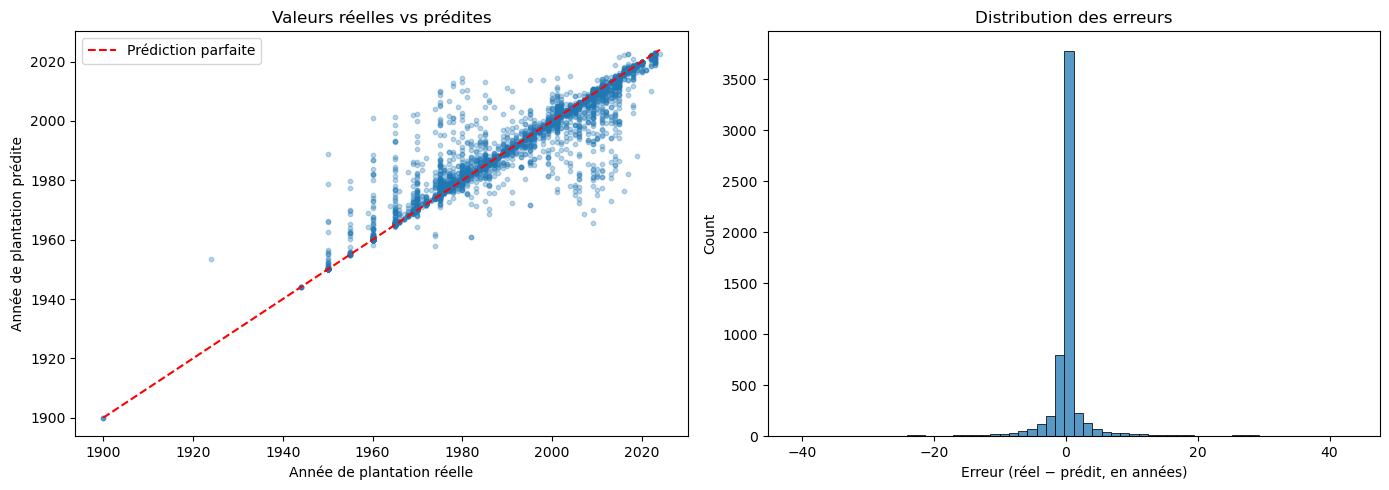

In [20]:
# Visualisation des prédictions.
best_model = grid_rf.best_estimator_
y_pred_test = best_model.predict(X_test)
residus = y_test - y_pred_test

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Réel vs prédit
axes[0].scatter(y_test, y_pred_test, alpha=0.3, s=10)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
             'r--', label='Prédiction parfaite')
axes[0].set_xlabel("Année de plantation réelle")
axes[0].set_ylabel("Année de plantation prédite")
axes[0].set_title("Valeurs réelles vs prédites")
axes[0].legend()

# Distribution des erreurs
sns.histplot(residus, bins=60, ax=axes[1])
axes[1].set_xlabel("Erreur (réel − prédit, en années)")
axes[1].set_title("Distribution des erreurs")

plt.tight_layout()
plt.show()

In [30]:
print((residus.abs() <= 1).mean())    # part des arbres à ≤ 1 an
print((residus.abs() <= 5).mean())    # part à ≤ 5 ans
print((residus.abs() > 20).mean())    # part des grosses erreurs
print(residus.mean())                 # biais moyen

0.7365391127666779
0.9012868269556383
0.02133423636979343
-0.006153911276666838


## 7. [OPTIONNEL] Importance des features

En utilisant la forêt aléatoire, comment peut-on savoir quelles sont les features les plus importantes ?

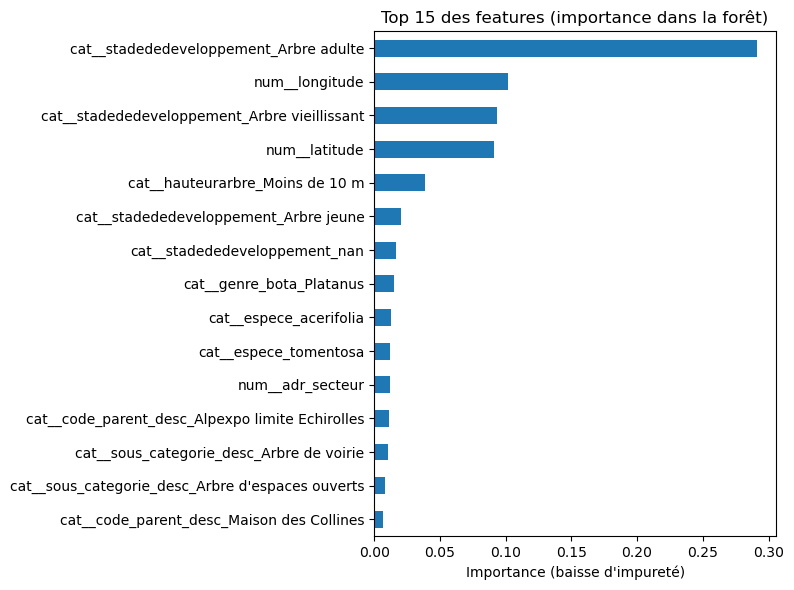

stadededeveloppement    0.421
code_parent_desc        0.158
longitude               0.102
latitude                0.091
espece                  0.072
genre_bota              0.050
hauteurarbre            0.045
sous_categorie_desc     0.024
adr_secteur             0.012
collectivite            0.009
dtype: float64


In [21]:
# Code, et à votre avis, comment c'etait calculé l'importance des features dans la forêt aléatoire ?
rf_best = grid_rf.best_estimator_
noms = rf_best.named_steps['prep'].get_feature_names_out()
imp = pd.Series(rf_best.named_steps['model'].feature_importances_, index=noms).sort_values(ascending=False)

plt.figure(figsize=(8, 6))
imp.head(15).sort_values().plot.barh()
plt.title("Top 15 des features (importance dans la forêt)")
plt.xlabel("Importance (baisse d'impureté)")
plt.tight_layout()
plt.show()

# Importance regroupée par colonne d'origine (les variables one-hot sont additionnées)
imp_col = imp.groupby(lambda n: next((c for c in cat_cols if n.startswith(f"cat__{c}_")), n.replace("num__", ""))).sum()
print(imp_col.sort_values(ascending=False).head(10).round(3))

Typiquement, on pourrait envisager de faire une backward elimination sur l'importance des features pour sélectionner le meilleur sous ensemble de features, mais cela peut-etre long si on a beaucoup de features et un modèle un peu long à entrainer comme c'est le cas ici. À la place on peut utiliser une regression avec regularisation lasso pour éliminer des features, avant de ré-entrainer une RandomForest sur les features sélectionnées. Créez un pipeline avec `LassoCV` comme selector et une RandomForest avec les meilleurs hyper-paramètres trouvés par la grid search en model. Évaluez sur le set de test.


In [22]:
# Code
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LassoCV

# Forêt avec les meilleurs hyperparamètres de la section 4
params_rf = {k.replace('model__', ''): v for k, v in grid_rf.best_params_.items()}

model_lasso_rf = Pipeline([
    ('prep', preprocessor),
    ('select', SelectFromModel(LassoCV(cv=5, max_iter=5000, random_state=42, n_jobs=-1))),
    ('model', RandomForestRegressor(random_state=42, n_jobs=-1, **params_rf))
])
model_lasso_rf.fit(X_train, y_train)

n_tot = len(model_lasso_rf.named_steps['prep'].get_feature_names_out())
n_gardees = model_lasso_rf.named_steps['select'].get_support().sum()
print(f"Features gardées : {n_gardees} / {n_tot}")

for nom, m in [("Forêt (GridSearch)", grid_rf.best_estimator_), ("Lasso + Forêt", model_lasso_rf)]:
    pred = m.predict(X_test)
    mse = mean_squared_error(y_test, pred)
    print(f"{nom} : MSE = {mse:.2f} | MAE = {mean_absolute_error(y_test, pred):.3f} | "
          f"RMSE = {np.sqrt(mse):.3f} | R² = {r2_score(y_test, pred):.3f}")

Features gardées : 524 / 1875
Forêt (GridSearch) : MSE = 26.62 | MAE = 1.855 | RMSE = 5.160 | R² = 0.918
Lasso + Forêt : MSE = 27.43 | MAE = 1.982 | RMSE = 5.238 | R² = 0.915


## 8. [OPTIONNEL] Comparez différents modèles de regression

Comparez plus de modèles de régression entre eux (par exemple en plus de la régression linéaire, des arbres de décision et des forets, la `LogisticRegression`, le `GradientBoostingRegressor`, et le plus récent `TabPFNRegressor` si vous avez le temps ( https://github.com/PriorLabs/TabPFN )), en faisant une recherche d'hyperparamètre adéquate à chaque modèle :

In [23]:
#Code, cherchez des examples pour trouver quels sont les hyper-parametres importants pour chaque modèle
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV

def pipe(m):
    return Pipeline([('prep', preprocessor), ('model', m)])

gs_ridge = GridSearchCV(pipe(Ridge()), {'model__alpha': [0.01, 0.1, 1, 10, 100]},
                        cv=kf, scoring='neg_mean_absolute_error', n_jobs=-1).fit(X_train, y_train)
print("Ridge →", gs_ridge.best_params_)

rs_gb = RandomizedSearchCV(
    pipe(GradientBoostingRegressor(random_state=42)),
    {'model__n_estimators': [100, 200],
     'model__learning_rate': [0.05, 0.1, 0.2],
     'model__max_depth': [3, 5, 8],
     'model__subsample': [0.8, 1.0]},
    n_iter=6, cv=3, scoring='neg_mean_absolute_error',
    n_jobs=-1, random_state=42, verbose=1).fit(X_train, y_train)
print("Gradient Boosting →", rs_gb.best_params_)

Ridge → {'model__alpha': 0.01}
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Gradient Boosting → {'model__subsample': 1.0, 'model__n_estimators': 200, 'model__max_depth': 8, 'model__learning_rate': 0.2}


Choisissez le modèle qui marche le mieux et ses meilleurs hyper-paramètres, sélectionnez le meilleur sous-ensemble de features pour ce modèle, et enfin refaites une dernière grid-search sur les hyper-paramètres de votre modèle avec les features retenues, pour obtenir votre modèle final. Évaluez sur le test set.

In [25]:
#Code
from sklearn.linear_model import LinearRegression
modeles = {
    'Régression linéaire': pipe(LinearRegression()),
    'Ridge': gs_ridge.best_estimator_,
    'Arbre': grid_dt.best_estimator_,
    'Forêt': grid_rf.best_estimator_,
    'Gradient Boosting': rs_gb.best_estimator_,
}

lignes = []
for nom, m in modeles.items():
    res = cross_validate(m, X_train, y_train, cv=kf, n_jobs=-1,
                         scoring=['neg_mean_squared_error', 'neg_mean_absolute_error', 'r2'])
    mse = -res['test_neg_mean_squared_error']
    lignes.append({'Modèle': nom,
                   'MAE': (-res['test_neg_mean_absolute_error']).mean(),
                   'RMSE': np.sqrt(mse).mean(),
                   'R²': res['test_r2'].mean()})

df_cmp = pd.DataFrame(lignes).set_index('Modèle').round(3).sort_values('MAE')
df_cmp

,MAE,RMSE,R²
Modèle,,,
Arbre,1.859,6.830,0.859
Forêt,2.077,5.594,0.906
Gradient Boosting,4.199,6.496,0.873
Ridge,4.698,7.535,0.829
Régression linéaire,4.700,7.552,0.828


In [26]:
from sklearn.base import clone

best_name = df_cmp.index[0]
print("Meilleur modèle :", best_name)

grids = {
    'Régression linéaire': {},
    'Ridge': {'model__alpha': [0.1, 1, 10]},
    'Arbre': {'model__min_samples_leaf': [1, 2, 5]},
    'Forêt': {'model__n_estimators': [200], 'model__min_samples_leaf': [1, 2],
              'model__max_features': [1.0, 0.5]},
    'Gradient Boosting': {'model__n_estimators': [100, 200], 'model__max_depth': [3, 5]},
}
grid_final_params = {**grids[best_name], 'select__threshold': ['median', 'mean']}

final_pipe = Pipeline([
    ('prep', preprocessor),
    ('select', SelectFromModel(RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))),
    ('model', clone(modeles[best_name].named_steps['model']))
])

grid_final = GridSearchCV(final_pipe, grid_final_params, cv=3,
                          scoring='neg_mean_absolute_error', n_jobs=-1, verbose=1)
grid_final.fit(X_train, y_train)
print("Meilleurs paramètres :", grid_final.best_params_)
print("Features gardées :", grid_final.best_estimator_.named_steps['select'].get_support().sum(), "/", n_tot)

# Évaluation finale sur le test, une seule fois
pred = grid_final.best_estimator_.predict(X_test)
mse = mean_squared_error(y_test, pred)
print(f"MODÈLE FINAL : MSE = {mse:.2f} | MAE = {mean_absolute_error(y_test, pred):.3f} | "
      f"RMSE = {np.sqrt(mse):.3f} | R² = {r2_score(y_test, pred):.3f}")

Meilleur modèle : Arbre
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Meilleurs paramètres : {'model__min_samples_leaf': 1, 'select__threshold': 'median'}
Features gardées : 938 / 1875
MODÈLE FINAL : MSE = 38.90 | MAE = 1.601 | RMSE = 6.237 | R² = 0.880


## Conclusion

## Conclusion

- **Données** : 23 620 arbres en train. Cible `anneedeplantation`, erreurs exprimées en années.
- **Baseline** : l'arbre de décision par défaut atteint un MAE de 1,63 an et un R² de 0,877 sur le test. La forêt par défaut atteint un MAE de 1,85 an et un R² de 0,918.
- **Arbre vs forêt** : la forêt est meilleure sur le RMSE (5,15 contre 6,31) et le R² : elle lisse les grosses erreurs. L'arbre est meilleur sur le MAE : il retrouve souvent l'année exacte.
- **GridSearchCV** : la grille de l'énoncé (`max_depth` ≤ 10, `min_samples_leaf` = 5 % ou 10 %) a dégradé les scores (MAE ≈ 10). Avec une grille élargie, la recherche a retrouvé les valeurs par défaut (`max_depth=None`, `min_samples_leaf=1`), sans gain. Le coût de la recherche pour la forêt a été de 21 min, contre 15 s pour l'arbre.
- **Erreurs** : elles sont rares mais grosses (≈ 1 % des arbres, jusqu'à 117 ans), sur des arbres anciens que les features n'expliquent pas. Le RMSE est donc bien supérieur au MAE.
- **Features** : les variables les plus importantes sont XX. La sélection par Lasso garde XX features sur XX, avec un score XX.
- **Comparaison de modèles** : le meilleur modèle est XX (MAE XX en CV). Modèle final avec sélection de features et grid search : MAE XX, RMSE XX, R² XX sur le test.
- **Limites et pistes** : feature engineering, `max_features` pour la forêt, traitement des arbres anciens.